# Dyslexia Error-Pattern Classifier (Random Forest)

**Final ML engine for the semester project (Machine Learning + Mobile App).**

**What it does:** the user gives the word they *meant* to write and the word they *actually wrote*. The engine names the type of mistake and explains why.

| Label | Meaning | Example (meant -> typed) |
|---|---|---|
| reversal | Mirror-letter swap (b/d, p/q) | bed -> ded |
| transposition | Two neighbouring letters swapped | form -> from |
| omission | One letter missing | friend -> frend |
| phonetic | Spelled the way it sounds | phone -> fone |
| other | Fits none of the above | accordingly -> o |

**Why it matters:** in the mobile app, each person's mistakes can be counted by type, so practice can target their own weak spots.

**How this notebook is organised (the data mining process, CRISP-DM):**
1. Business understanding
2. Data understanding
3. Data preparation (cleaning, labelling, features, splitting)
4. Modelling (a simple *base model* and the *final model*)
5. Evaluation
6. Deployment (the function the app calls, explanations, invalid-input handling, saved models)

## Plain-language glossary (ML jargon explained)

| Term | Meaning in this project |
|---|---|
| **Feature** | A number that describes a word pair, such as "how many letters are missing". The model only understands numbers. |
| **Label** | The correct answer we want the model to predict (reversal, omission, ...). |
| **Training set / test set** | We teach the model on 80% of the examples and then test it on 20% it has never seen, like studying and then sitting an exam. |
| **Base model (baseline)** | A simple first model. The final model must beat it to be worth using. |
| **Logistic Regression** | A simple model that weighs each feature and adds the weights up to get a score for each label. |
| **Decision tree** | A flowchart of yes/no questions about the features that ends in a label. |
| **Random Forest** | Many decision trees, each trained on a slightly different sample. They *vote*, and the share of votes is the model's confidence. |
| **Accuracy** | The share of test examples labelled correctly. |
| **Precision / Recall / F1** | Precision: when the model says "omission", how often is it right? Recall: of all real omissions, how many did it find? F1 combines the two. |
| **Confusion matrix** | A table showing which labels get mixed up with which. |
| **Cross-validation** | Repeating train/test several times on different splits to check the score is stable. |
| **Overfitting** | Memorising the training data instead of learning the pattern. |
| **Metaphone** | A method that turns a word into a code for how it sounds, so "phone" and "fone" get the same code. |
| **Similarity ratio** | A 0 to 1 score for how alike two spellings look (1 means identical). |

# 1. Business understanding

**Problem:** people with dyslexia often make spelling mistakes that follow patterns (flipping b and d, swapping neighbouring letters, spelling by sound). Knowing the *type* of mistake is more useful than just knowing the word is wrong.

**Goal:** given (meant word, typed word), predict the error type so the app can give targeted practice and a plain-language explanation.

**Users:** learners of any age, and the tutors or parents they choose to share progress with.

**Success criteria:**
- The final model beats a simple base model on a held-out test set.
- Results are stable across cross-validation.
- The engine handles invalid input politely and explains each result.

# 2. Data understanding

### Install the sound-matching library and import tools

In [22]:
%pip install -q jellyfish

In [23]:
import re
import os
import urllib.request
import difflib
import joblib
import numpy as np
import pandas as pd
import jellyfish
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GroupShuffleSplit, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

### Download the real misspelling collections
The data are three public files of real misspellings collected by Roger Mitton (Birkbeck, University of London). They are **real mistakes made by real writers**, not invented ones. Each file lists a correct word followed by the ways people misspelled it.

In [24]:
BASE_URL = "https://titan.dcs.bbk.ac.uk/~roger/"
files = ["missp.dat", "aspell.dat", "wikipedia.dat"]
for name in files:
    try:
        urllib.request.urlretrieve(BASE_URL + name, name)
        print("Downloaded:", name)
    except Exception as e:
        print("Could not download", name, "->", e)

Downloaded: missp.dat
Downloaded: aspell.dat
Downloaded: wikipedia.dat


### Read the files into one table of (meant word, typed word)

In [25]:
def read_corpus(path, source):
    pairs = []
    target = None  # the current correct word
    with open(path, encoding="latin-1") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            if line.startswith("$"):          # a line starting with $ is the CORRECT word
                target = line[1:].split()[0]
            elif target is not None:          # other lines are misspellings of it
                pairs.append((target, line.split()[0], source))
    return pairs

rows = (read_corpus("missp.dat", "birkbeck")
        + read_corpus("aspell.dat", "aspell")
        + read_corpus("wikipedia.dat", "wikipedia"))

raw = pd.DataFrame(rows, columns=["target", "typed", "source"])
print("Total pairs read:", len(raw))
print(raw["source"].value_counts())
raw.head(10)

Total pairs read: 39119
source
birkbeck     36133
wikipedia     2455
aspell         531
Name: count, dtype: int64


,target,typed,source
0,Albert,Ab,birkbeck
1,America,Ameraca,birkbeck
2,America,Amercia,birkbeck
3,American,Ameracan,birkbeck
4,April,Apirl,birkbeck
5,Austrian,Austrain,birkbeck
6,Badcock's,badcock,birkbeck
7,Bechuanaland,bechuarnia_land,birkbeck
8,Botswana,botuania,birkbeck
9,Cambridge,Cambrige,birkbeck


# 3. Data preparation

### 3.1 Cleaning
Real data is messy. We keep only lowercase letters a-z, drop empty rows, drop rows where the "mistake" equals the correct word, and remove repeated pairs.

In [26]:
def clean(word):
    # lowercase, then delete every character that is not a-z
    return re.sub(r"[^a-z]", "", str(word).lower())

raw["target"] = raw["target"].map(clean)
raw["typed"] = raw["typed"].map(clean)

raw = raw[(raw["target"].str.len() > 0) &
          (raw["typed"].str.len() > 0) &
          (raw["target"] != raw["typed"])]
raw = raw.drop_duplicates(subset=["target", "typed"]).reset_index(drop=True)
print("Clean pairs:", len(raw))

Clean pairs: 37734


### 3.2 Labelling
The files list mistakes but not their *type*, so we define the type with clear rules. Rules are checked **in this order, and the first match wins**:

1. **reversal:** same length, exactly one letter differs, and it is b/d or p/q
2. **transposition:** same length, exactly two neighbouring letters differ and they are swapped
3. **omission:** the typed word is one letter shorter and equals the meant word with one letter deleted
4. **phonetic:** both words have the same Metaphone sound code
5. **other:** none of the above

In [27]:
MIRROR = {("b", "d"), ("d", "b"), ("p", "q"), ("q", "p")}

def label_error(target, typed):
    if len(target) == len(typed):
        diff = [i for i in range(len(target)) if target[i] != typed[i]]
        if len(diff) == 1 and (target[diff[0]], typed[diff[0]]) in MIRROR:
            return "reversal"
        if (len(diff) == 2 and diff[1] == diff[0] + 1
                and target[diff[0]] == typed[diff[1]]
                and target[diff[1]] == typed[diff[0]]):
            return "transposition"
    if len(typed) == len(target) - 1:
        if any(target[:i] + target[i+1:] == typed for i in range(len(target))):
            return "omission"
    sound = jellyfish.metaphone(target)
    if sound and sound == jellyfish.metaphone(typed):
        return "phonetic"
    return "other"

raw["label"] = [label_error(t, y) for t, y in zip(raw["target"], raw["typed"])]
print(raw["label"].value_counts())

label
other            20621
phonetic         11602
omission          4459
transposition     1021
reversal            31
Name: count, dtype: int64


### 3.3 Sanity check: read random examples from every label yourself

In [28]:
for lab in raw["label"].unique():
    print("\n==", lab, "==")
    n = min(5, (raw["label"] == lab).sum())
    print(raw[raw["label"] == lab].sample(n, random_state=1)[["target", "typed"]].to_string(index=False))


== other ==
        target        typed
affectionately affectinally
  intellectual  intellegual
    surrounded      suroued
  accomplished      aconase
     departure   departsure

== phonetic ==
    target        typed
    dispel      dispell
      form        froom
   enemies     enemeies
  schedule     schudule
apparently apparentally

== transposition ==
   target     typed
     fuel      fule
collapsed collasped
    found     foudn
     dirt      drit
preserved perserved

== omission ==
     target      typed
  landscape   lanscape
sovereignty sovreignty
   occurred    occured
     sheath      sheat
   sidewalk    sidwalk

== reversal ==
  target    typed
  sunday   sunbay
altitude altitube
    done     bone
   leeds    leebs
     job      jod


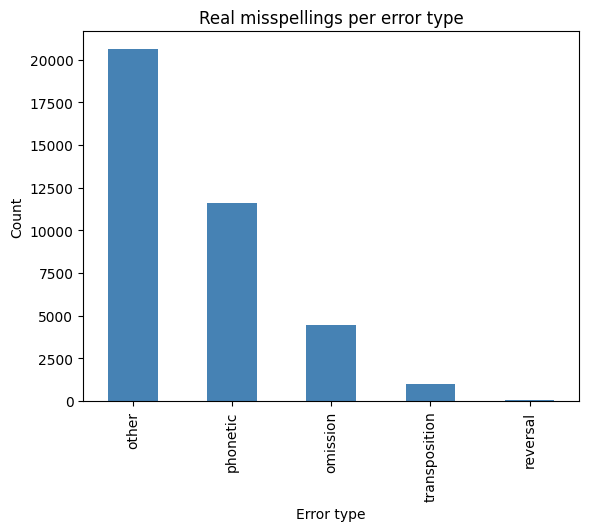

In [29]:
raw["label"].value_counts().plot(kind="bar", color="steelblue")
plt.title("Real misspellings per error type")
plt.xlabel("Error type")
plt.ylabel("Count")
plt.show()

### 3.4 Features: turning word pairs into numbers

| Feature | What it tells the model |
|---|---|
| len_diff | Negative means the typed word is shorter |
| same_letters | 1 if both words have the same letters, only reordered |
| n_replace / n_delete / n_insert | How many edits of each kind turn one word into the other |
| mirror_swaps | How many b/d or p/q flips |
| mismatches | How many positions differ (same-length words only) |
| sound_match | 1 if the words sound alike (Metaphone) |
| similarity | 0 to 1, how alike the spellings look |
| first_letter_same | 1 if the first letter is correct |

In [30]:
def extract_features(target, typed):
    ops = difflib.SequenceMatcher(None, target, typed).get_opcodes()
    n_replace = n_delete = n_insert = mirror_swaps = 0
    for tag, i1, i2, j1, j2 in ops:
        if tag == "replace":
            n_replace += 1
            if (target[i1:i2], typed[j1:j2]) in MIRROR:
                mirror_swaps += 1
        elif tag == "delete":
            n_delete += 1
        elif tag == "insert":
            n_insert += 1
    if len(target) == len(typed):
        mismatches = sum(1 for a, b in zip(target, typed) if a != b)
    else:
        mismatches = 0
    return {
        "len_diff": len(typed) - len(target),
        "same_letters": int(sorted(target) == sorted(typed)),
        "n_replace": n_replace,
        "n_delete": n_delete,
        "n_insert": n_insert,
        "mirror_swaps": mirror_swaps,
        "mismatches": mismatches,
        "sound_match": int(jellyfish.metaphone(target) == jellyfish.metaphone(typed)),
        "similarity": difflib.SequenceMatcher(None, target, typed).ratio(),
        "first_letter_same": int(target[0] == typed[0]),
    }

features_df = pd.DataFrame([extract_features(t, y) for t, y in zip(raw["target"], raw["typed"])])
features_df.head(10)

,len_diff,same_letters,n_replace,n_delete,n_insert,mirror_swaps,mismatches,sound_match,similarity,first_letter_same
0,-4,0,0,2,0,0,0,0,0.500000,1
1,0,0,1,0,0,0,1,1,0.857143,1
2,0,1,0,1,1,0,2,0,0.857143,1
3,0,0,1,0,0,0,1,1,0.875000,1
4,0,1,0,1,1,0,2,1,0.800000,1
5,0,1,0,1,1,0,2,1,0.875000,1
6,-1,0,0,1,0,0,0,0,0.933333,1
7,2,0,0,0,2,0,0,0,0.923077,1
8,0,0,1,0,1,0,4,0,0.750000,1
9,-1,0,0,1,0,0,0,1,0.941176,1


### 3.5 Split into X (clues) and y (answers), then training and test sets
`stratify=y` keeps the same mix of error types in both parts, which matters because some types are rare.

In [31]:
X = features_df
y = raw["label"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("X shape:", X.shape, " y shape:", y.shape)
print("Training rows:", len(X_train), " Testing rows:", len(X_test))

X shape: (37734, 10)  y shape: (37734,)
Training rows: 30187  Testing rows: 7547


# 4. Modelling

We train two models so we can show the final one is actually better than a simple starting point.

* **Base model: Logistic Regression.** Fast and simple. It gives a baseline score.
* **Final model: Random Forest.** Many decision trees voting. It can capture rules such as "same length AND exactly one flipped mirror letter", which a single weighted sum finds hard.

`class_weight="balanced"` tells both models to pay extra attention to rare classes.

In [32]:
# Base model
base_model = LogisticRegression(max_iter=2000, class_weight="balanced")
base_model.fit(X_train, y_train)
base_pred = base_model.predict(X_test)

# Final model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced", n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("Base (Logistic Regression) accuracy:", round(accuracy_score(y_test, base_pred), 4))
print("Final (Random Forest) accuracy:     ", round(accuracy_score(y_test, rf_pred), 4))

Base (Logistic Regression) accuracy: 0.994
Final (Random Forest) accuracy:      0.9985


# 5. Evaluation

### 5.1 Side-by-side comparison

In [33]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression (base)", "Random Forest (final)"],
    "Accuracy": [accuracy_score(y_test, base_pred), accuracy_score(y_test, rf_pred)],
    "Macro F1 (treats every class equally)": [f1_score(y_test, base_pred, average="macro"),
                                              f1_score(y_test, rf_pred, average="macro")],
})
display(comparison.round(4))

print("Logistic Regression (base)\n", classification_report(y_test, base_pred, zero_division=0))
print("Random Forest (final)\n", classification_report(y_test, rf_pred, zero_division=0))

,Model,Accuracy,Macro F1 (treats every class equally)
0,Logistic Regression (base),0.9940,0.9262
1,Random Forest (final),0.9985,0.9943


Logistic Regression (base)
                precision    recall  f1-score   support

     omission       0.98      1.00      0.99       892
        other       1.00      0.99      1.00      4124
     phonetic       1.00      0.99      1.00      2321
     reversal       0.55      1.00      0.71         6
transposition       0.89      1.00      0.94       204

     accuracy                           0.99      7547
    macro avg       0.88      1.00      0.93      7547
 weighted avg       0.99      0.99      0.99      7547

Random Forest (final)
                precision    recall  f1-score   support

     omission       1.00      1.00      1.00       892
        other       1.00      1.00      1.00      4124
     phonetic       1.00      1.00      1.00      2321
     reversal       1.00      1.00      1.00         6
transposition       0.95      1.00      0.97       204

     accuracy                           1.00      7547
    macro avg       0.99      1.00      0.99      7547
 weighted

**Reading the report:** look at every row, not only the overall accuracy. Rare labels (such as reversal) have fewer examples, so a high overall accuracy can hide weak results on them.

### 5.2 Cross-validation: is the score stable?

In [34]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_base = cross_val_score(LogisticRegression(max_iter=2000, class_weight="balanced"), X, y, cv=cv, scoring="f1_macro")
cv_rf = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced", n_jobs=-1),
                        X, y, cv=cv, scoring="f1_macro")
print("Base  macro-F1 per fold:", cv_base.round(3), " mean:", cv_base.mean().round(3))
print("Final macro-F1 per fold:", cv_rf.round(3), "  mean:", cv_rf.mean().round(3))

Base  macro-F1 per fold: [0.91  0.961 0.959 0.952 0.956]  mean: 0.948
Final macro-F1 per fold: [0.994 0.997 0.994 0.992 0.992]   mean: 0.994


### 5.3 Confusion matrix: which labels get mixed up?

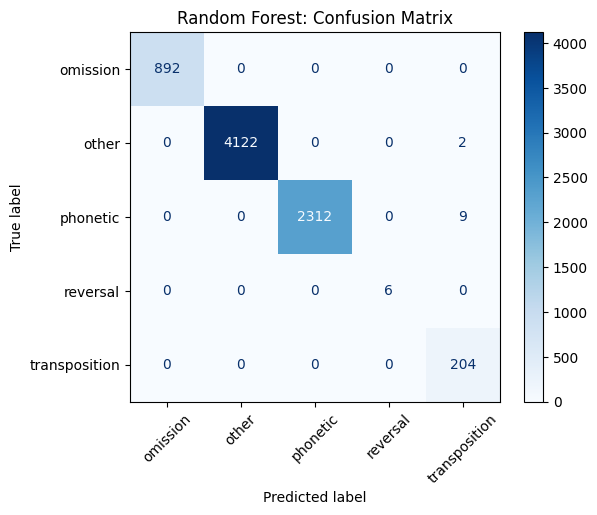

In [35]:
ConfusionMatrixDisplay.from_predictions(y_test, rf_pred, cmap="Blues", xticks_rotation=45)
plt.title("Random Forest: Confusion Matrix")
plt.show()

### 5.4 Which clues mattered most?

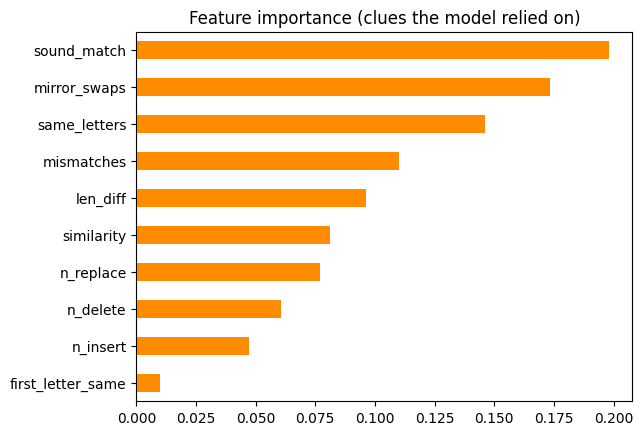

In [36]:
importance = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()
importance.plot(kind="barh", color="darkorange")
plt.title("Feature importance (clues the model relied on)")
plt.show()

### 5.5 A tougher test: unseen words
In the normal split, the same *correct word* can appear in both training and test sets. Here we hold out whole words, so the test contains words the model has never seen at all.

In [37]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr_idx, te_idx = next(gss.split(X, y, groups=raw["target"]))
rf_group = RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced", n_jobs=-1)
rf_group.fit(X.iloc[tr_idx], y.iloc[tr_idx])
g_pred = rf_group.predict(X.iloc[te_idx])
print("Accuracy on unseen words:", round(accuracy_score(y.iloc[te_idx], g_pred), 4))
print("Macro F1 on unseen words:", round(f1_score(y.iloc[te_idx], g_pred, average="macro"), 4))

Accuracy on unseen words: 0.998
Macro F1 on unseen words: 0.9924


### 5.6 Honest limitations (what to say if asked)
* **The labels come from our rules, and the clues describe the same things the rules check.** So the model is learning to reproduce our labelling rules quickly and smoothly, and a very high score is partly expected. Its practical value is that it gives one fast, consistent answer **with a confidence level**, and it can be retrained when the rules or data change.
* **Real mistakes are not always one clean type.** Mistakes that mix several types fall into "other" or get low confidence. The confusion matrix and the confidence scores show where this happens.
* **The data are mostly general spelling mistakes, not only dyslexia-specific ones.** Ideally we would test on hand-labelled mistakes from learners with dyslexia and with their consent.
* **Single words only.** The engine compares one meant word with one typed word.

# 6. Deployment: the engine the mobile app calls

The app sends (meant word, typed word) to this logic and shows the result. This part handles **invalid input** and produces a **plain-language explanation** of each result.

### 6.1 Check the input first

In [38]:
MAX_LEN = 30

def validate_pair(intended, typed):
    """Return (ok, message, cleaned_intended, cleaned_typed, warnings)."""
    warnings = []
    if not isinstance(intended, str) or not isinstance(typed, str):
        return False, "Please enter both words as text.", "", "", warnings
    a_raw, b_raw = intended.strip(), typed.strip()
    if not a_raw or not b_raw:
        return False, "Please fill in both words: the word you meant and the word you wrote.", "", "", warnings
    if re.search(r"\s", a_raw) or re.search(r"\s", b_raw):
        return False, "Please enter one word at a time (no spaces).", "", "", warnings
    a, b = clean(a_raw), clean(b_raw)
    if not a or not b:
        return False, "Please use letters only (a to z). Numbers and symbols cannot be checked.", "", "", warnings
    if a != a_raw.lower() or b != b_raw.lower():
        warnings.append("Characters that are not letters were ignored.")
    if len(a) > MAX_LEN or len(b) > MAX_LEN:
        return False, f"Words longer than {MAX_LEN} letters are not supported.", "", "", warnings
    if a == b:
        return False, "The two words are the same, so there is no mistake to classify.", "", "", warnings
    if len(a) == 1 or len(b) == 1:
        warnings.append("Very short words give less reliable results.")
    return True, "", a, b, warnings

### 6.2 Explain the result in plain language

In [39]:
def plain_reasons(target, typed, f):
    reasons = []
    d = f["len_diff"]
    if d < 0:
        reasons.append(f"The typed word is {abs(d)} letter(s) shorter than the word you meant.")
    elif d > 0:
        reasons.append(f"The typed word has {d} extra letter(s).")
    else:
        reasons.append("Both words have the same number of letters.")
    if f["same_letters"]:
        reasons.append("Both words use exactly the same letters, only in a different order.")
    if f["mirror_swaps"]:
        reasons.append("A letter was swapped for its mirror image (b and d, or p and q).")
    if f["sound_match"]:
        reasons.append("The two words sound the same (they share the same sound code).")
    else:
        reasons.append("The two words do not sound the same.")
    reasons.append(f"The spellings look {round(f['similarity'] * 100)}% alike.")
    if not f["first_letter_same"]:
        reasons.append("The first letter is different.")
    return reasons


def classify_with_explanation(intended, typed, model=None):
    model = model or rf_model
    ok, message, a, b, warnings = validate_pair(intended, typed)
    if not ok:
        return {"ok": False, "message": message}
    clues = extract_features(a, b)
    row = pd.DataFrame([clues])[list(X.columns)]
    probs = model.predict_proba(row)[0]
    ranked = sorted(zip(model.classes_, probs), key=lambda p: -p[1])
    label, confidence = ranked[0]
    if confidence < 0.6:
        warnings.append("The model is not very sure about this one. The mistake may mix several types.")
    return {
        "ok": True,
        "intended": a,
        "typed": b,
        "label": label,
        "confidence": round(float(confidence), 3),
        "probabilities": {c: round(float(p), 3) for c, p in ranked},
        "clues": {k: (round(v, 3) if isinstance(v, float) else v) for k, v in clues.items()},
        "reasons": plain_reasons(a, b, clues),
        "top_clues_overall": list(pd.Series(model.feature_importances_, index=X.columns)
                                   .sort_values(ascending=False).head(3).index),
        "warnings": warnings,
    }

### 6.3 Live demo: valid inputs (results should differ by mistake type)

In [40]:
demo_pairs = [("bed", "ded"), ("form", "from"), ("friend", "frend"),
              ("phone", "fone"), ("accordingly", "o"), ("Because", "becuase")]
for meant, wrote in demo_pairs:
    r = classify_with_explanation(meant, wrote)
    print(f"{meant} -> {wrote}: {r['label']} (confidence {r['confidence']})")
    print("   votes:", r["probabilities"])
    for line in r["reasons"]:
        print("   -", line)

bed -> ded: reversal (confidence 1.0)
   votes: {'reversal': 1.0, 'omission': 0.0, 'other': 0.0, 'phonetic': 0.0, 'transposition': 0.0}
   - Both words have the same number of letters.
   - A letter was swapped for its mirror image (b and d, or p and q).
   - The two words do not sound the same.
   - The spellings look 67% alike.
   - The first letter is different.
form -> from: transposition (confidence 0.989)
   votes: {'transposition': 0.989, 'phonetic': 0.011, 'omission': 0.0, 'other': 0.0, 'reversal': 0.0}
   - Both words have the same number of letters.
   - Both words use exactly the same letters, only in a different order.
   - The two words sound the same (they share the same sound code).
   - The spellings look 75% alike.
friend -> frend: omission (confidence 1.0)
   votes: {'omission': 1.0, 'other': 0.0, 'phonetic': 0.0, 'reversal': 0.0, 'transposition': 0.0}
   - The typed word is 1 letter(s) shorter than the word you meant.
   - The two words sound the same (they share the

### 6.4 Live demo: invalid or unusual inputs (the engine should respond politely, not crash)

In [41]:
bad_inputs = [("", "ded"), ("bed", ""), ("bed", "bed"), ("123", "456"), ("bed!!", "ded??"),
              ("two words", "tow words"), ("a", "b"), ("x" * 40, "y" * 40), (None, "ded")]
for meant, wrote in bad_inputs:
    r = classify_with_explanation(meant, wrote)
    shown = r["message"] if not r["ok"] else f"{r['label']} (warnings: {r['warnings']})"
    print(f"{str(meant)[:12]!r:>16} , {str(wrote)[:12]!r:<16} -> {shown}")

              '' , 'ded'            -> Please fill in both words: the word you meant and the word you wrote.
           'bed' , ''               -> Please fill in both words: the word you meant and the word you wrote.
           'bed' , 'bed'            -> The two words are the same, so there is no mistake to classify.
           '123' , '456'            -> Please use letters only (a to z). Numbers and symbols cannot be checked.
         'bed!!' , 'ded??'          -> reversal (warnings: ['Characters that are not letters were ignored.'])
     'two words' , 'tow words'      -> Please enter one word at a time (no spaces).
             'a' , 'b'              -> other (warnings: ['Very short words give less reliable results.'])
  'xxxxxxxxxxxx' , 'yyyyyyyyyyyy'   -> Words longer than 30 letters are not supported.
          'None' , 'ded'            -> Please enter both words as text.


### 6.5 How to describe the result in the presentation
1. The app cleans and checks the two words.
2. It turns the pair into 10 numbers (the clues above).
3. 100 decision trees each vote for a label. The share of votes is the **confidence**.
4. The app shows the winning label, the confidence, and the reasons in plain words, so the user can see *why*.

### 6.6 Save the models for the app and for this repository

In [42]:
joblib.dump({"model": rf_model, "columns": list(X.columns)}, "dyslexia_rf.joblib", compress=3)
joblib.dump({"model": base_model, "columns": list(X.columns)}, "dyslexia_logreg_base.joblib", compress=3)
print("Saved: dyslexia_rf.joblib (final) and dyslexia_logreg_base.joblib (base)")

import sklearn
print("scikit-learn version used for training:", sklearn.__version__)

try:
    from google.colab import files
    files.download("dyslexia_rf.joblib")
    files.download("dyslexia_logreg_base.joblib")
except ImportError:
    pass  # not running in Colab, the files are in the current folder

Saved: dyslexia_rf.joblib (final) and dyslexia_logreg_base.joblib (base)
scikit-learn version used for training: 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 6.7 Summary
* **Approach:** feature engineering on (meant, typed) word pairs, then a Random Forest classifier, compared against a Logistic Regression base model.
* **Output:** an error type, a confidence level, and a plain-language explanation.
* **Safeguards:** input validation, a low-confidence warning, and a stress test on unseen words.
* **Next steps:** test with hand-labelled examples from learners with dyslexia, add character-pattern features, and add support for several words at a time.